# PYR – Vizualizace dat v R z Pythonu


In [1]:
from pathlib import Path
import os, sys
for root in (Path.cwd(), *Path.cwd().parents):
    if (root / '.notebook_deps').is_dir():
        sys.path.insert(0, str(root / '.notebook_deps'))
        break
if os.name == 'nt' and not os.environ.get('R_HOME'):
    candidates = list(Path('C:/Program Files/R').glob('R-*'))
    if candidates:
        os.environ['R_HOME'] = str(max(candidates, key=lambda p: tuple(int(x) for x in p.name[2:].split('.'))))
os.environ.setdefault('RPY2_CFFI_MODE', 'ABI')
_dll_handles = []
if os.name == 'nt' and os.environ.get('R_HOME'):
    for sub in ('bin/x64', 'bin'):
        d = Path(os.environ['R_HOME']) / sub
        if d.is_dir():
            _dll_handles.append(os.add_dll_directory(str(d)))
            os.environ['PATH'] = str(d) + os.pathsep + os.environ['PATH']
import rpy2.robjects as ro
from IPython.display import display, Image
BASE = Path.cwd()
if not (BASE / 'data/Student Mental Health Analysis During Online Learning.csv').exists():
    BASE = BASE / '05_11_2026'
DATA = BASE / 'data/Student Mental Health Analysis During Online Learning.csv'
assert DATA.is_file(), f'Chybí dataset: {DATA}'
OUT = BASE / 'vystup'
OUT.mkdir(exist_ok=True)
ro.globalenv['csv_path'] = str(DATA.resolve()).replace('\\', '/')
R = ro.r
if os.name == "nt":
    R('Sys.setlocale("LC_CTYPE", ".UTF-8")')

def rplot(source, name):
    """Spustí R kód na PNG zařízení, uzavře zařízení i při chybě a zobrazí obrázek."""
    path = OUT / f'{name}.png'
    ro.globalenv['plot_path'] = str(path.resolve()).replace('\\', '/')
    R('png(plot_path, width=1500, height=1000, res=130)')
    try:
        R('par(mar=c(6, 6, 4, 2), family="sans", las=1)')
        R(source)
    finally:
        R('dev.off()')
    display(Image(filename=str(path)))
print('Python:', sys.version.split()[0], '|', R('R.version.string')[0])

R callback write-console: In addition:   
R callback write-console: Warning message:
  
R callback write-console: In Sys.setlocale("LC_CTYPE", ".UTF-8") :  
R callback write-console: 
   
R callback write-console:  using locale code page other than 1250 may cause problems
  
Python: 3.15.0 | R version 4.6.1 (2026-06-24 ucrt)


In [2]:
R(r'''
mh <- read.csv(csv_path, check.names=FALSE, stringsAsFactors=FALSE,
               fileEncoding="UTF-8-BOM", na.strings=c("", "NA", "N/A"))
required <- c("Name", "Gender", "Age", "Education Level", "Screen Time (hrs/day)",
 "Sleep Duration (hrs)", "Physical Activity (hrs/week)", "Stress Level",
 "Anxious Before Exams", "Academic Performance Change")
stopifnot(all(required %in% names(mh)), nrow(mh)>0)
for (nm in names(mh)) if(is.character(mh[[nm]])) mh[[nm]] <- trimws(mh[[nm]])
for(nm in c("Age", "Screen Time (hrs/day)", "Sleep Duration (hrs)", "Physical Activity (hrs/week)")) {
 stopifnot(is.numeric(mh[[nm]]), all(is.finite(mh[[nm]]) | is.na(mh[[nm]])))
 stopifnot(all(mh[[nm]] >= 0, na.rm=TRUE))
}
stopifnot(all(mh$`Screen Time (hrs/day)`<=24, na.rm=TRUE),
          all(mh$`Sleep Duration (hrs)`<=24, na.rm=TRUE))
check_levels <- function(x, allowed) stopifnot(all(na.omit(x) %in% allowed))
check_levels(mh$`Stress Level`, c("Low","Medium","High"))
check_levels(mh$`Academic Performance Change`, c("Declined","Same","Improved"))
edu_order <- c("Class 8","Class 9","Class 10","Class 11","Class 12","BA","BSc","BTech","MA","MSc","MTech")
check_levels(mh$`Education Level`, edu_order)
mh$`Education Level` <- factor(mh$`Education Level`, levels=edu_order)
mh$`Stress Level` <- factor(mh$`Stress Level`, levels=c("Low","Medium","High"), ordered=TRUE)
mh$`Academic Performance Change` <- factor(mh$`Academic Performance Change`,
 levels=c("Declined","Same","Improved"), ordered=TRUE)
cat("Počet respondentů:", nrow(mh), " | Počet proměnných:", ncol(mh), "\n")
audit <- data.frame(promenna=names(mh), chybi=sapply(mh, function(x) sum(is.na(x))),
                   ruznych=sapply(mh, function(x) length(unique(na.omit(x)))))
print(audit, row.names=FALSE)
cat("Přesně duplicitní řádky:", sum(duplicated(mh)), "\n")

''')

Počet respondentů: 1000  | Počet proměnných: 10 
                     promenna chybi ruznych
                         Name     0      30
                       Gender     0       3
                          Age     0      12
              Education Level     0      11
        Screen Time (hrs/day)     0     101
         Sleep Duration (hrs)     0      51
 Physical Activity (hrs/week)     0     101
                 Stress Level     0       3
         Anxious Before Exams     0       2
  Academic Performance Change     0       3
Přesně duplicitní řádky: 0 


## 1. Typy proměnných a vhodná vizualizace

| Proměnná | Typ měření | Vhodné grafy a důvod |
|---|---|---|
| Name | nominální identifikátor | Zpravidla neplotovat; jméno není unikátní ID. Sloupce pouze pro četnosti jmen, které nejsou cílem analýzy. |
| Gender | nominální | Sloupcový graf počtů nebo podílů, kategorie nemají přirozené pořadí. |
| Age | poměrová, zde zaznamenaná v celých letech | Histogram, boxplot; přirozená nula a smysluplné rozdíly i poměry věku. |
| Education Level | uspořádané stupně + nominální obory | Sloupcový graf, případně 100% skládaný graf. Školní třídy mají pořadí, BA/BSc/BTech jsou různé obory stejného stupně, obdobně MA/MSc/MTech. Nelze všem kategoriím přiřadit rovnoměrnou číselnou vzdálenost. |
| Screen Time (hrs/day) | poměrová | Histogram, boxplot, bodový graf proti spánku; nula znamená nulovou dobu. |
| Sleep Duration (hrs) | poměrová | Histogram, boxplot, bodový graf; délka spánku má přirozenou nulu. |
| Physical Activity (hrs/week) | poměrová | Histogram, boxplot, bodový graf; doba aktivity s přirozenou nulou. |
| Stress Level | ordinální: Low < Medium < High | Uspořádaný sloupcový graf; vzdálenosti mezi úrovněmi neznáme, průměr kódů není vhodný. |
| Anxious Before Exams | nominální binární | Sloupcový graf podílů Yes/No, případně rozdělení podle vzdělání. |
| Academic Performance Change | ordinální: Declined < Same < Improved | Uspořádaný nebo 100% skládaný sloupcový graf; změna je kategoriální, ne číselná známka. |

V původních sloupcích není čistě intervalová veličina bez přirozené nuly. Chybějící hodnoty se neimputují: každý graf používá dostupná pozorování příslušných proměnných. Počty vyloučených záznamů jsou vypsány níže. Jména respondentů nezobrazujeme.


In [3]:
R(r'''
cat("Souhrn číselných proměnných:\n")
print(summary(mh[c("Age", "Screen Time (hrs/day)", "Sleep Duration (hrs)", "Physical Activity (hrs/week)")]))

''')

Souhrn číselných proměnných:
      Age        Screen Time (hrs/day) Sleep Duration (hrs)
 Min.   :15.00   Min.   : 2.000        Min.   :4.000       
 1st Qu.:17.00   1st Qu.: 4.400        1st Qu.:5.100       
 Median :20.00   Median : 6.900        Median :6.500       
 Mean   :20.34   Mean   : 6.909        Mean   :6.451       
 3rd Qu.:23.00   3rd Qu.: 9.500        3rd Qu.:7.700       
 Max.   :26.00   Max.   :12.000        Max.   :9.000       
 Physical Activity (hrs/week)
 Min.   : 0.000              
 1st Qu.: 2.600              
 Median : 5.000              
 Mean   : 5.018              
 3rd Qu.: 7.600              
 Max.   :10.000              


## 2. Rozdělení Stress Level a Lie factor

**Korektnější je graf B**, protože osa četností začíná nulou. Graf A ořezává spodní část sloupců, takže vizuálně přehání relativní rozdíly. Pořadí High–Low–Medium navíc neodpovídá ordinální škále; redesign používá Low–Medium–High.

Lie factor = relativní změna zobrazené délky / relativní změna dat. Pro srovnání nejnižší a nejvyšší četnosti (High a Medium) použijeme:

`LF = (((n_max − b)/(n_min − b)) − 1) / ((n_max/n_min) − 1)`.

U B je základna `b = 0`, tedy **LF = 1**. U A lze ze spodního okraje obrázku odhadnout **b ≈ 160**; přesnou mez nelze z rastrového obrázku doložit. Proto LF pro A uvádíme jako **odhad**, nikoli přesnou vlastnost neznámého zdrojového grafu. Výsledek závisí i na zvolené dvojici sloupců; zde je dvojice výslovně určená.


In [4]:
R(r'''
stress <- table(mh$`Stress Level`)
print(stress)
lo <- min(stress); hi <- max(stress)
lie <- function(b) (((hi-b)/(lo-b))-1)/((hi/lo)-1)
print(data.frame(graf=c("A (odhad b=160)","B (b=0)"), LF=c(lie(160),lie(0))))
cat("Citlivost na odečet základny A:\n")
print(data.frame(zakladna=c(155,160,165), LF=sapply(c(155,160,165), lie)))
cat("Vyloučeno kvůli chybějícímu stresu:", sum(is.na(mh$`Stress Level`)), "\n")

''')


   Low Medium   High 
   327    492    181 
             graf       LF
1 A (odhad b=160) 8.619048
2         B (b=0) 1.000000
Citlivost na odečet základny A:
  zakladna        LF
1      155  6.961538
2      160  8.619048
3      165 11.312500
Vyloučeno kvůli chybějícímu stresu: 0 


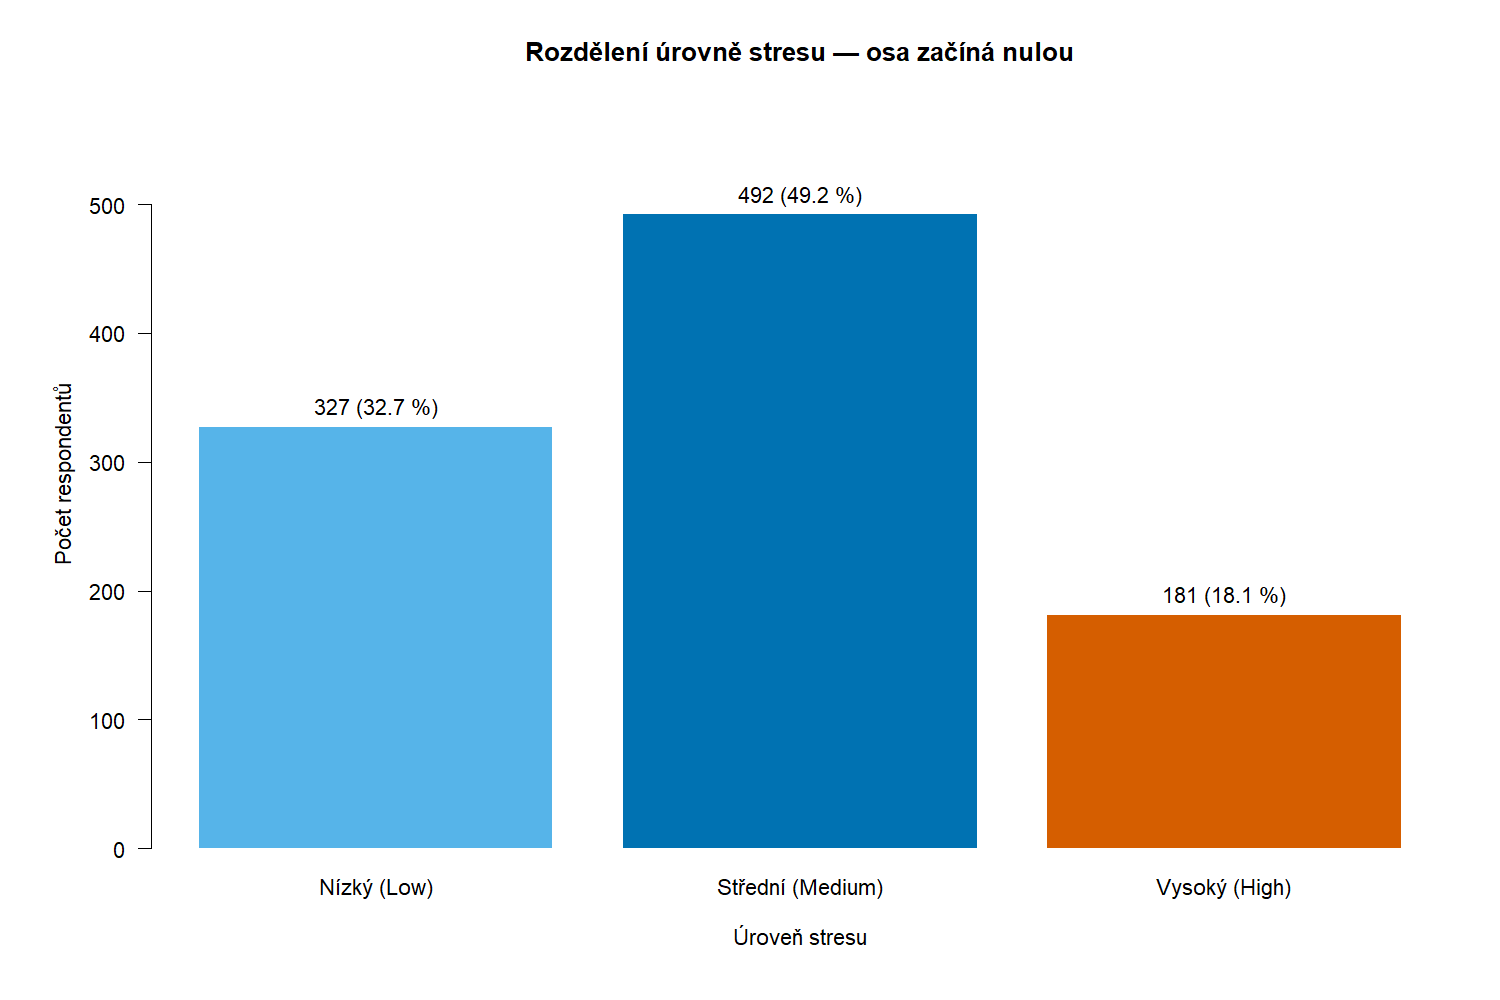

In [5]:
rplot(r'''
bp <- barplot(stress, col=c("#56B4E9","#0072B2","#D55E00"),
 ylim=c(0, max(stress)*1.18), ylab="Počet respondentů", xlab="Úroveň stresu",
 names.arg=c("Nízký (Low)","Střední (Medium)","Vysoký (High)"),
 main="Rozdělení úrovně stresu — osa začíná nulou", border=NA)
text(bp, stress, labels=paste0(stress, " (", round(100*stress/sum(stress),1), " %)"), pos=3)

''', "02_stres")

## 3. Změna studijních výsledků podle vzdělání

**Graf B (100% skládané sloupce)** lépe porovnává strukturu skupin různé velikosti. Graf A ukazuje absolutní počty, které závisejí také na počtu respondentů v jednotlivých skupinách.

Legenda: **Změna studijních výsledků** – Zhoršení, Beze změny, Zlepšení. Segmenty i legenda mají stejné pořadí od zhoršení ke zlepšení. Vzdělání řadíme podle tříd a stupňů, obory uvnitř stupně necháváme jako samostatné kategorie. U každého sloupce je uvedeno platné `n`; procenta se počítají uvnitř skupiny z dostupné změny výkonu.


In [6]:
R(r'''
ok3 <- complete.cases(mh[c("Education Level","Academic Performance Change")])
cat("Úloha 3 — vyloučeno:", sum(!ok3), "\n")
tab3 <- table(mh$`Academic Performance Change`[ok3], mh$`Education Level`[ok3])
tab3 <- tab3[, colSums(tab3)>0, drop=FALSE]
prop3 <- sweep(tab3, 2, colSums(tab3), "/")
print(round(100*prop3,1))

''')

Úloha 3 — vyloučeno: 0 
          
           Class 8 Class 9 Class 10 Class 11 Class 12   BA  BSc BTech   MA  MSc
  Declined    32.0    31.0     31.0     38.6     23.4 22.6 31.8  31.0 30.2 26.1
  Same        40.0    36.8     49.4     35.2     48.9 40.3 36.5  41.7 38.8 39.9
  Improved    28.0    32.2     19.5     26.1     27.7 37.1 31.8  27.4 31.0 34.1
          
           MTech
  Declined  28.7
  Same      37.8
  Improved  33.6


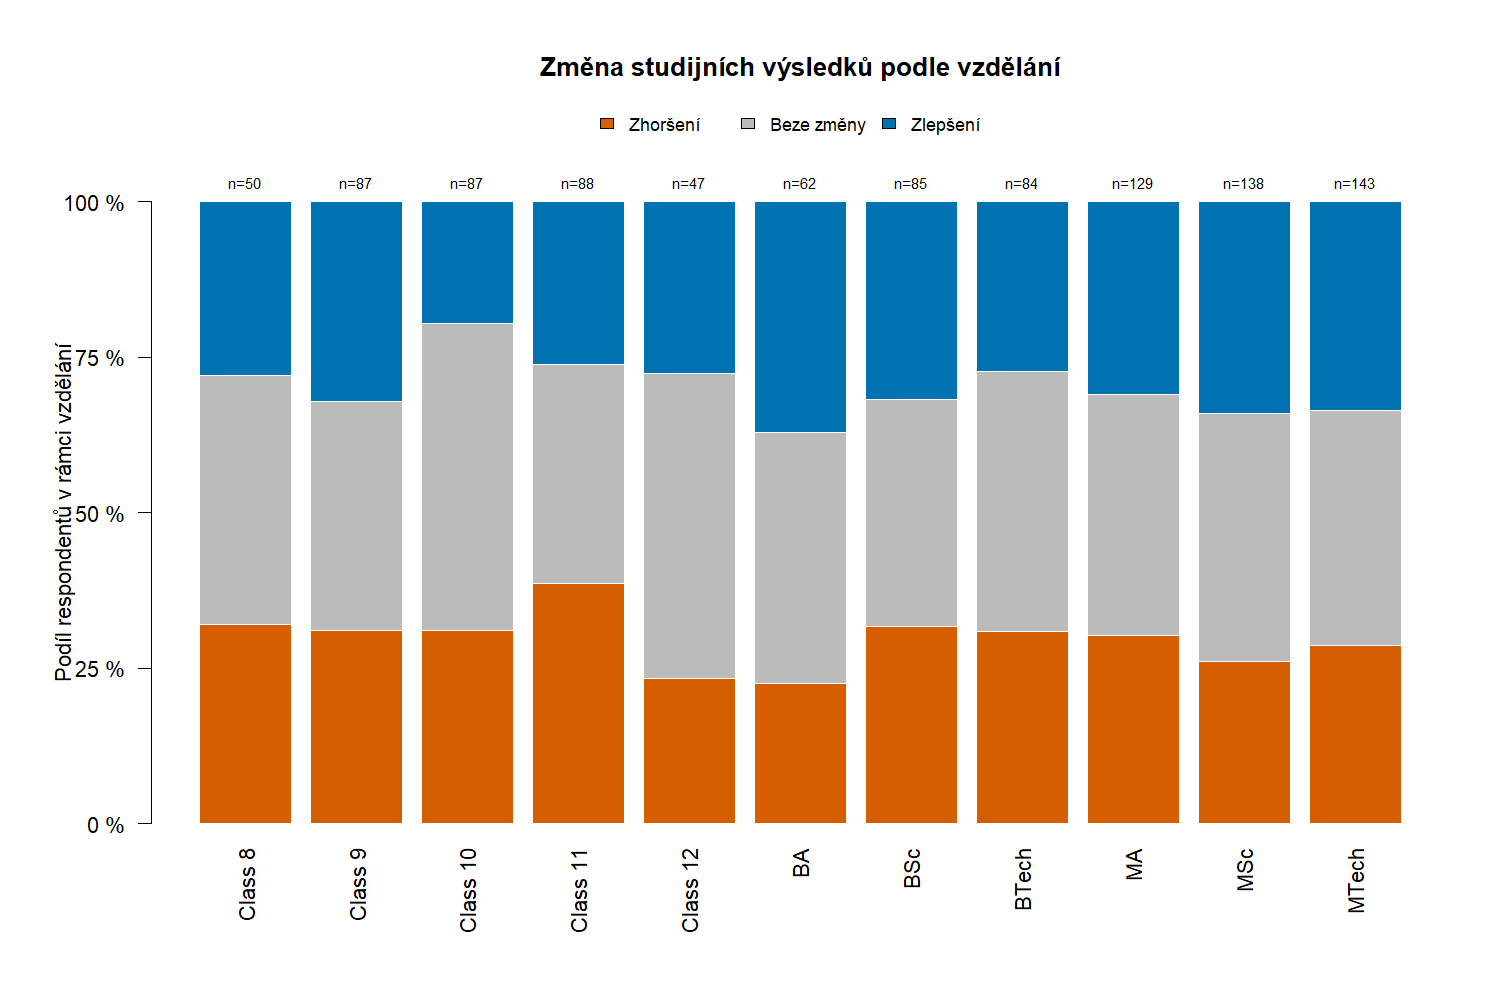

In [7]:
rplot(r'''
par(mar=c(7,6,8,2))
bp <- barplot(prop3, col=c("#D55E00","#BBBBBB","#0072B2"), border="white",
 ylim=c(0,1), yaxt="n", ylab="Podíl respondentů v rámci vzdělání", las=2,
 main="")
title("Změna studijních výsledků podle vzdělání", line=5)
axis(2, at=seq(0,1,.25), labels=paste0(seq(0,100,25)," %"), las=1)
text(bp, 1, paste0("n=",colSums(tab3)), pos=3, xpd=NA, cex=.7)
legend("top", inset=c(0,-.16), xpd=NA, horiz=TRUE, bty="n",
 legend=c("Zhoršení","Beze změny","Zlepšení"), fill=c("#D55E00","#BBBBBB","#0072B2"), cex=.85)

''', "03_vysledky")

## 4. Heatmapa času u obrazovky a spánku

**Vhodnější je graf B s paletou viridis.** Barva zde vyjadřuje nezáporný počet, proto je vhodná sekvenční škála s uspořádaným jasem. Duha vytváří zdánlivé hranice a nemá jednoznačně rostoucí jas.

Použijeme intervaly šířky **1 hodina** na obou osách, aby zůstaly čitelné. Popisky uvádějí přímo hranice intervalů a jednotky. `[a; b)` zahrnuje dolní mez, poslední interval zahrnuje i horní mez. Mřížka obsahuje i prázdné kombinace s nulovým počtem. Součet buněk musí odpovídat počtu platných dvojic.


In [8]:
R(r'''
screen <- mh$`Screen Time (hrs/day)`; sleep <- mh$`Sleep Duration (hrs)`
ok4 <- complete.cases(screen,sleep)
breaks1 <- function(x) {
 a <- floor(min(x)); b <- ceiling(max(x)); if(a==b) b <- a+1
 seq(a,b,by=1)
}
bx <- breaks1(screen[ok4]); by <- breaks1(sleep[ok4])
scr_bin <- cut(screen[ok4], bx, right=FALSE, include.lowest=TRUE)
slp_bin <- cut(sleep[ok4], by, right=FALSE, include.lowest=TRUE)
counts <- table(scr_bin,slp_bin)
stopifnot(sum(counts)==sum(ok4))
interval_labels <- function(b) paste0("[", head(b,-1), "; ",tail(b,-1),
 c(rep(")", length(b)-2),"]"))
xl <- interval_labels(bx); yl <- interval_labels(by)
cat("Úloha 4/5 — platných dvojic:",sum(ok4),"; vyloučeno:",sum(!ok4),"\n")
heat <- function(z, cols, zlim, title, key, band=FALSE) {
 layout(matrix(c(1,2),nrow=1), widths=c(5,1))
 par(mar=c(8,7,4,1))
 image(seq_len(nrow(z)), seq_len(ncol(z)), z, col=cols, zlim=zlim,
       axes=FALSE, xlab="", ylab="", main=title)
 axis(1,seq_len(nrow(z)),xl,las=2,cex.axis=.75)
 axis(2,seq_len(ncol(z)),yl,las=1,cex.axis=.8)
 mtext("Čas u obrazovky: intervaly [h/den]",1,6)
 mtext("Délka spánku: intervaly [h]",2,5,las=0)
 box()
 if(band) {
   # Zvýrazňujeme všechny řádky, jejichž interval má kladný průnik s [6.5,7.5].
   rows <- which(head(by,-1)<7.5 & tail(by,-1)>6.5)
   for(j in rows) rect(.5,j-.5,nrow(z)+.5,j+.5,border="black",lwd=2,lty=2)
 }
 par(mar=c(8,1,4,5))
 zz <- seq(zlim[1],zlim[2],length.out=length(cols))
 image(1,zz,matrix(zz,nrow=1),col=cols,zlim=zlim,axes=FALSE,xlab="",ylab="")
 axis(4,las=1); mtext(key,4,3,las=0); box()
 layout(1)
}

''')

Úloha 4/5 — platných dvojic: 1000 ; vyloučeno: 0 


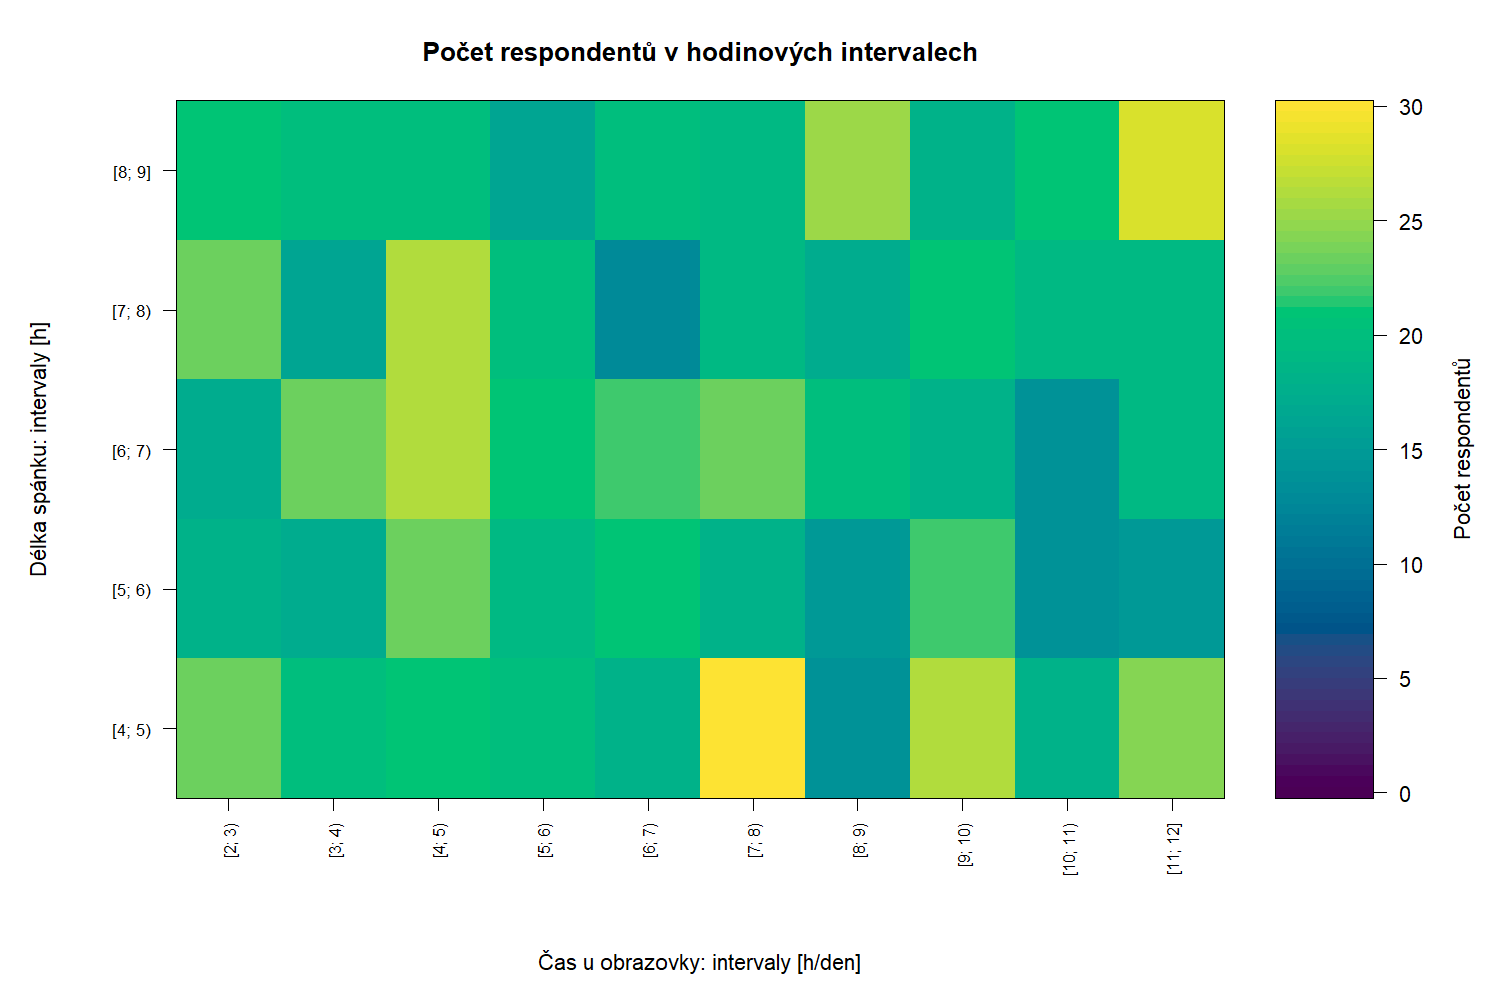

In [9]:
rplot(r'''
heat(counts, hcl.colors(64,"viridis"), c(0,max(counts)),
 "Počet respondentů v hodinových intervalech", "Počet respondentů")

''', "04_heatmapa")

## 5. Odchylka spánku od referenčních 7 hodin

**Vhodnější je graf B s divergentní škálou a neutrální nulou.** Barva rozlišuje směr i velikost odchylky: modrá kratší spánek, bílá blízkost reference, oranžová delší spánek. Limity barev jsou symetrické kolem nuly.

V každé buňce počítáme **průměr individuálních odchylek `Sleep Duration − 7`**, nikoli odchylku středu intervalu. Prázdné buňky zůstanou šedé. Přerušované rámečky označují intervaly protínající pásmo 6,5–7,5 h; přesný podíl respondentů v tomto pásmu vypočítáme z jednotlivých hodnot.

Sedm hodin přebíráme jako **referenční hodnotu zadání**. Pásmo ±0,5 h je pouze pomocná anotace, nikoli doložená „bezpečná“ zóna pro všechny věkové skupiny. Odchylka spánku je z definice závislá na ose spánku; podobnost barev v řádcích sama o sobě nedokládá vztah k času u obrazovky.


In [10]:
R(r'''
delta <- sleep[ok4]-7
mean_delta <- tapply(delta, list(scr_bin,slp_bin), mean)
stopifnot(identical(dim(mean_delta),dim(counts)))
lim <- max(abs(mean_delta),na.rm=TRUE); if(lim==0) lim <- .5
in_band <- abs(sleep-7)<=.5
cat(sprintf("Pásmo 6,5–7,5 h: %d / %d respondentů (%.1f %%) s dostupným spánkem.\n",
 sum(in_band,na.rm=TRUE), sum(!is.na(sleep)), 100*mean(in_band,na.rm=TRUE)))

''')

Pásmo 6,5–7,5 h: 233 / 1000 respondentů (23.3 %) s dostupným spánkem.


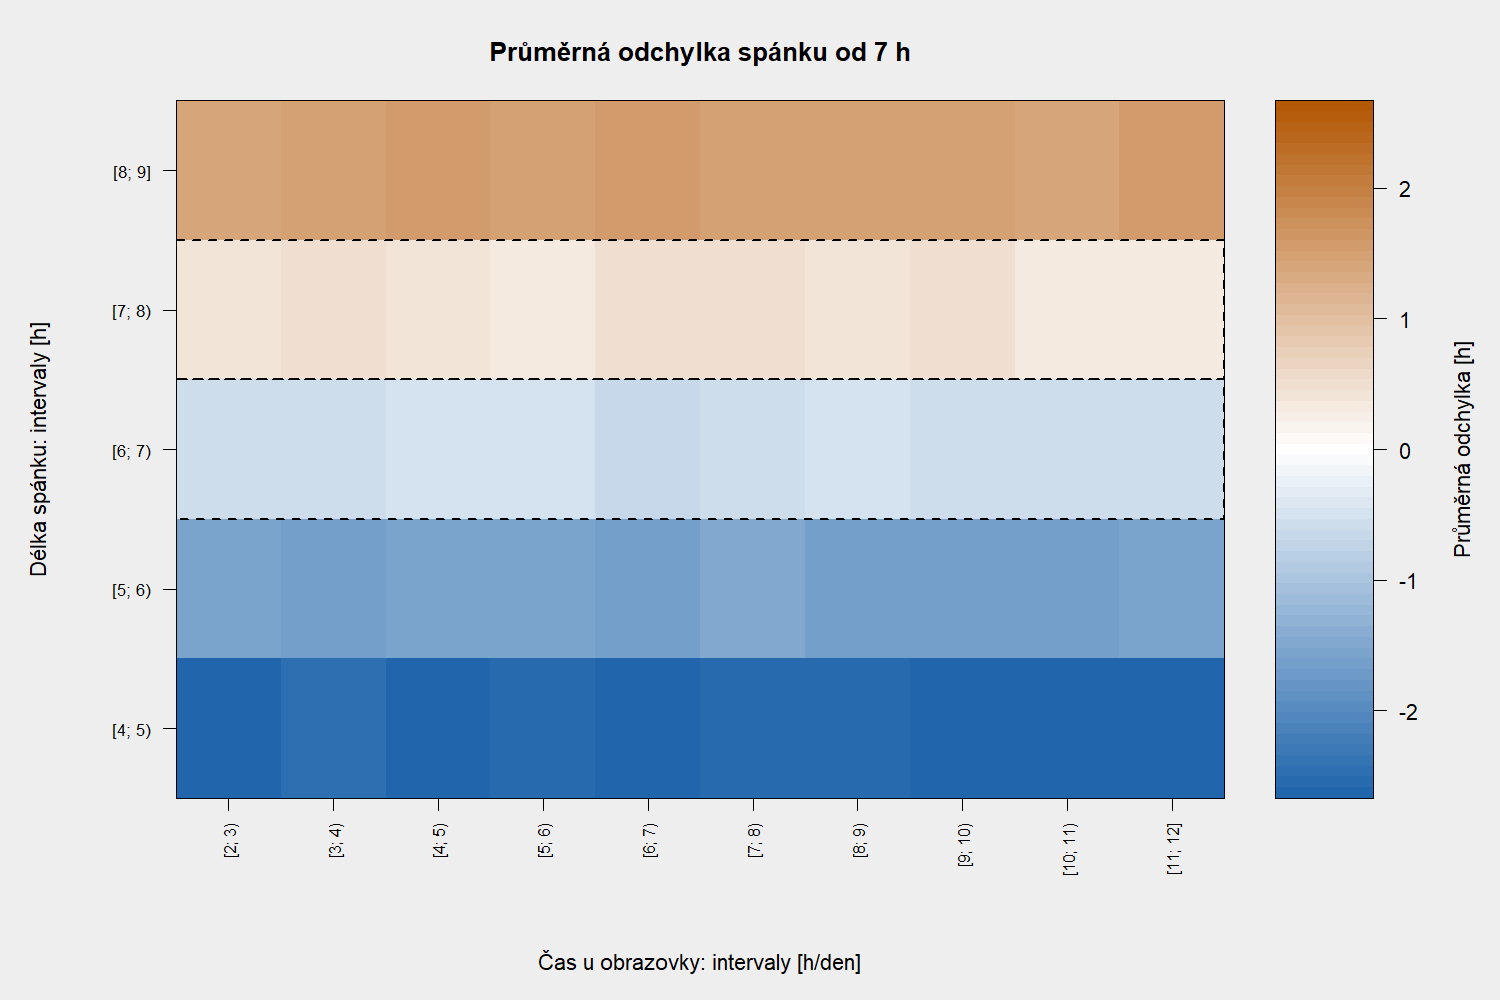

In [11]:
rplot(r'''
par(bg="#EEEEEE")
heat(mean_delta, colorRampPalette(c("#2166AC","#FFFFFF","#B35806"))(65), c(-lim,lim),
 "Průměrná odchylka spánku od 7 h", "Průměrná odchylka [h]", band=TRUE)

''', "05_odchylka")

## 6. Podíl vysokého stresu a nejistota

**Férovější pro porovnání napříč vzděláním je graf B – podíl.** Absolutní počet silně závisí na velikosti skupiny. Jmenovatel tvoří respondenti dané úrovně vzdělání se známou úrovní stresu; čitatel zahrnuje `High`. Skupiny s nulovým počtem High zůstanou zahrnuté.

Použijeme bodový graf s **95% Wilsonovým intervalem spolehlivosti pro binomický podíl**, který se chová lépe než jednoduchý Waldův interval zejména u menších skupin a hodnot blízko 0 nebo 1. V popisku je `High / n`. Osa podílu je společná 0–100 %.

Intervaly popisují nejistotu při předpokladu nezávislých binomických pozorování; nezahrnují výběrové zkreslení či chybu dotazníku. Nejde o důkaz příčinnosti ani o současné intervaly pro všechny skupiny. Překryv intervalů sám není formálním testem rozdílů.


In [12]:
R(r'''
ok6 <- complete.cases(mh[c("Education Level","Stress Level")])
tab6 <- table(mh$`Education Level`[ok6],mh$`Stress Level`[ok6])
tab6 <- tab6[rowSums(tab6)>0,,drop=FALSE]
n <- rowSums(tab6); k <- tab6[,"High"]; phat <- k/n
z <- qnorm(.975); den <- 1+z^2/n
center <- (phat+z^2/(2*n))/den
half <- z*sqrt(phat*(1-phat)/n+z^2/(4*n^2))/den
high <- data.frame(vzdelani=rownames(tab6), high=as.integer(k), n=as.integer(n),
 podil=as.numeric(phat), dolni=as.numeric(center-half), horni=as.numeric(center+half))
stopifnot(all(high$dolni>=0),all(high$horni<=1),sum(high$n)==sum(ok6))
print(high, row.names=FALSE, digits=4)
cat("Úloha 6 — vyloučeno:",sum(!ok6),"\n")
write.csv(high, file.path(dirname(plot_path), "podil_high_wilson.csv"), row.names=FALSE)

''')

 vzdelani high   n  podil   dolni  horni
  Class 8    9  50 0.1800 0.09770 0.3080
  Class 9   12  87 0.1379 0.08070 0.2258
 Class 10   14  87 0.1609 0.09835 0.2522
 Class 11   16  88 0.1818 0.11513 0.2751
 Class 12    8  47 0.1702 0.08886 0.3014
       BA   17  62 0.2742 0.17881 0.3959
      BSc   14  85 0.1647 0.10072 0.2577
    BTech   21  84 0.2500 0.16972 0.3521
       MA   23 129 0.1783 0.12185 0.2533
      MSc   26 138 0.1884 0.13194 0.2617
    MTech   21 143 0.1469 0.09810 0.2141
Úloha 6 — vyloučeno: 0 


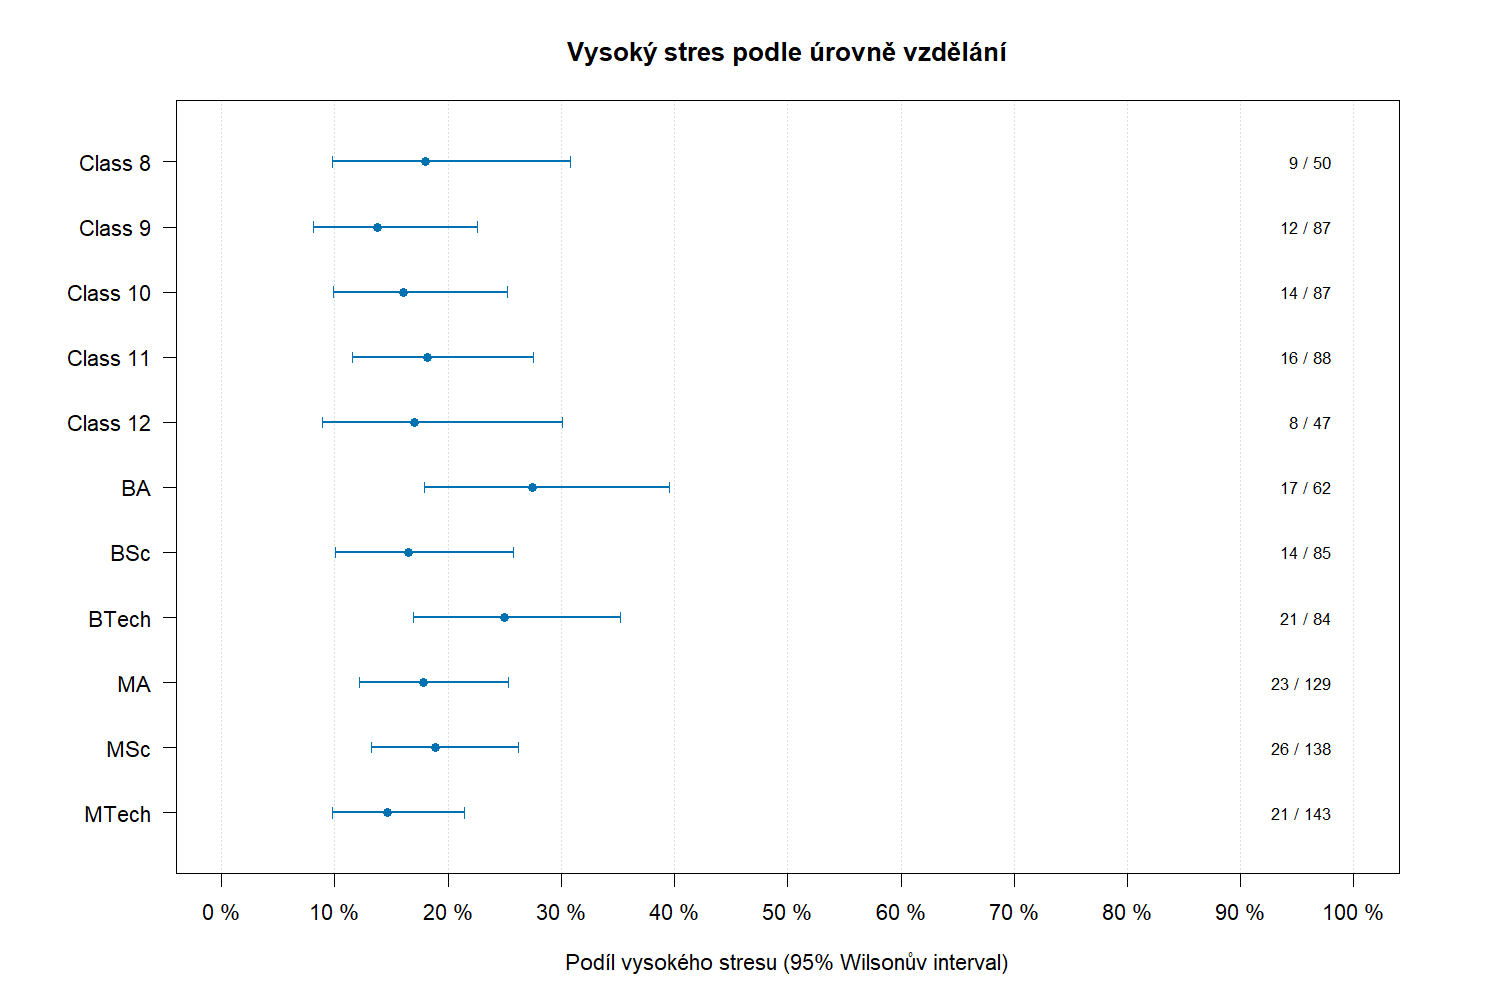

In [13]:
rplot(r'''
par(mar=c(5,7,4,4))
y <- rev(seq_len(nrow(high)))
plot(high$podil,y,xlim=c(0,1),ylim=c(.5,nrow(high)+.5),pch=19,col="#0072B2",
 axes=FALSE,xlab="Podíl vysokého stresu (95% Wilsonův interval)",ylab="",
 main="Vysoký stres podle úrovně vzdělání")
axis(1,seq(0,1,.1),paste0(seq(0,100,10)," %"))
axis(2,y,high$vzdelani,las=1)
abline(v=seq(0,1,.1),col="#DDDDDD",lty=3)
segments(high$dolni,y,high$horni,y,col="#0072B2",lwd=2)
segments(high$dolni,y-.08,high$dolni,y+.08,col="#0072B2")
segments(high$horni,y-.08,high$horni,y+.08,col="#0072B2")
points(high$podil,y,pch=19,col="#0072B2")
text(.98,y,paste0(high$high," / ",high$n),adj=1,cex=.8)
box()

''', "06_high_wilson")

## Výsledky a reprodukovatelnost
Následující souhrn se počítá přímo z načtených dat. Výsledky popisují tento dataset a neumožňují příčinné závěry. Obrázky jsou vloženy do notebooku a zároveň uloženy ve složce `vystup`; zdrojový kód je součástí buněk tohoto notebooku.


In [14]:
R(r'''
cat(sprintf("Nejčetnější stres: %s (%d z %d, %.1f %%).\n",names(which.max(stress)),max(stress),sum(stress),100*max(stress)/sum(stress)))
i <- which.max(high$podil)
cat(sprintf("Nejvyšší pozorovaný podíl High: %s, %.1f %% (95%% IS %.1f–%.1f %%; %d/%d).\n",
 high$vzdelani[i],100*high$podil[i],100*high$dolni[i],100*high$horni[i],high$high[i],high$n[i]))
cat("Nejvyšší bodový odhad sám o sobě neprokazuje statisticky významný rozdíl.\n")
print(sessionInfo())

''')

Nejčetnější stres: Medium (492 z 1000, 49.2 %).
Nejvyšší pozorovaný podíl High: BA, 27.4 % (95% IS 17.9–39.6 %; 17/62).
Nejvyšší bodový odhad sám o sobě neprokazuje statisticky významný rozdíl.
R version 4.6.1 (2026-06-24 ucrt)
Platform: x86_64-w64-mingw32/x64
Running under: Windows 11 x64 (build 26200)

Matrix products: default
  LAPACK version 3.12.1

locale:
[1] LC_COLLATE=C                LC_CTYPE=Czech_Czechia.utf8
[3] LC_MONETARY=C               LC_NUMERIC=C               
[5] LC_TIME=C                  
system code page: 1250

time zone: Europe/Prague
tzcode source: internal

attached base packages:
[1] tools     stats     graphics  grDevices utils     datasets  methods  
[8] base     

loaded via a namespace (and not attached):
[1] compiler_4.6.1
